# Sequential (greedy) per-sample input sensitivity analysis

Greedy conditional leave-one-out (LOCO) sensitivity: at each step, the input
token whose NaN-masking maximizes the prediction change vs the full-input
baseline is selected per sample, kept masked, and the process repeats
(like PCA's n_components, but for input tokens).

- Deterministic predictions: error = MSE between baseline and masked prediction.
- Probabilistic (mu, raw_sigma) heads: error = 2-Wasserstein distance between
  the Gaussian predictions (accounts for variance), or KL divergence.
- Output: one row per test sample, columns sens_k / err_k / err_pct_k.

Memory note (optimized backend): candidates are evaluated in parallel via
batch expansion, so peak GPU memory scales with
batch_size * chunk_size * L^2 * n_heads (attention scores dominate).
chunk_size=None derives a safe value from max_chunk_memory_mb, and on CUDA
OOM the chunk is automatically halved and retried. Reduce
max_chunk_memory_mb (or set a small chunk_size) if your GPU is tight.

References: Lei et al. 2018 (LOCO); Covert et al. 2020 (SAGE);
Sturmfels et al. 2021 (removal-based explanations); Borgonovo 2007
(moment-independent sensitivity).

In [27]:
from os.path import dirname, abspath, join
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from proT.proj_specific.GSA.sequential_sensitivity import get_config_and_best_checkpoint
from proT.proj_specific.GSA.sequential_sensitivity import get_sequential_sensitivity_df

ROOT_DIR = dirname(abspath(''))
datadir_path = join(ROOT_DIR, 'data/input')
experiment_path = join(ROOT_DIR, 'experiments/baseline_optuna/euler/baseline_proT_dyconex_sum_50908169')
output_path = join(ROOT_DIR, 'experiments/evaluations/sequential_sensitivity/df_seq_sens.csv')

config, checkpoint_path = get_config_and_best_checkpoint(experiment_path)

In [28]:
# Run the analysis (optimized backend: single model load, batch expansion),
# or load cached results from output_path if they already exist.
# values_to_mask=None -> all variable ids present in the split (excl. padding 0).
# error_metric='auto' -> W2 for Gaussian heads, MSE for deterministic ones.
from os.path import exists

FORCE_RECOMPUTE = False  # set True to ignore the cache and recompute

if exists(output_path) and not FORCE_RECOMPUTE:
    df_seq = pd.read_csv(output_path)
    print(f"Loaded cached results from {output_path}")
else:
    df_seq = get_sequential_sensitivity_df(
        config=config,
        datadir_path=datadir_path,
        checkpoint_path=checkpoint_path,
        n_most_sensitive=10,
        values_to_mask=None,
        split='test',
        error_metric='auto',
        backend='optimized',
        chunk_size=None,  # auto from max_chunk_memory_mb; halved+retried on OOM
        max_chunk_memory_mb=2048,  # per-chunk GPU memory budget (reduce if tight)
        output_path=output_path,  # function writes the CSV cache here
    )
df_seq.head()

Loaded cached results from c:\Users\ScipioneFrancesco\Documents\Projects\proT\experiments/evaluations/sequential_sensitivity/df_seq_sens.csv


,sample_idx,sens_1,err_1,err_pct_1,sens_2,err_2,err_pct_2,sens_3,err_3,err_pct_3,...,err_pct_7,sens_8,err_8,err_pct_8,sens_9,err_9,err_pct_9,sens_10,err_10,err_pct_10
0,0,10,6.497853e-05,0.071553,209,0.000189,0.207651,71,0.000594,0.654473,...,1.180230,225,0.001166,1.284271,98,0.001255,1.382372,186,0.001309,1.440932
1,1,269,9.100718e-07,0.001019,277,0.000004,0.004133,305,0.000008,0.008645,...,0.025924,273,0.000028,0.031147,309,0.000033,0.036755,293,0.000038,0.043088
2,2,298,3.374323e-06,0.003158,269,0.000008,0.007758,277,0.000016,0.014708,...,0.041349,305,0.000051,0.047950,8,0.000059,0.055382,293,0.000068,0.063710
3,3,287,3.159984e-05,0.038549,295,0.000119,0.144680,331,0.000215,0.261957,...,1.040722,311,0.000880,1.074034,299,0.000908,1.108097,337,0.000931,1.135592
4,4,10,5.299127e-03,2.753526,42,0.013010,6.760163,156,0.015201,7.898824,...,11.294974,95,0.021866,11.361789,96,0.021988,11.425335,33,0.022095,11.480817


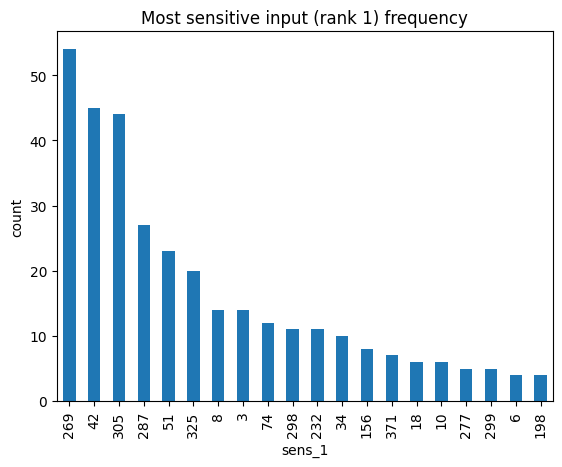

In [29]:
# Most frequently selected 1st-most-sensitive variable across test samples
df_seq['sens_1'].value_counts().head(20).plot(kind='bar')
plt.ylabel('count'); plt.title('Most sensitive input (rank 1) frequency')
plt.show()

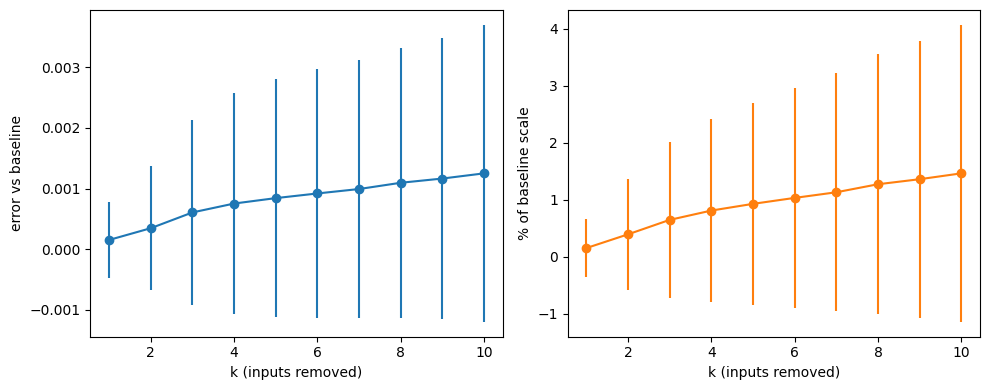

In [30]:
# Mean +/- std of the error (and % of baseline) as a function of k
err_cols = [c for c in df_seq.columns if c.startswith('err_') and not c.startswith('err_pct')]
pct_cols = [c for c in df_seq.columns if c.startswith('err_pct_')]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].errorbar(range(1, len(err_cols) + 1), df_seq[err_cols].mean(),
               yerr=df_seq[err_cols].std(), marker='o')
ax[0].set_xlabel('k (inputs removed)'); ax[0].set_ylabel('error vs baseline')
ax[1].errorbar(range(1, len(pct_cols) + 1), df_seq[pct_cols].mean(),
               yerr=df_seq[pct_cols].std(), marker='o', color='tab:orange')
ax[1].set_xlabel('k (inputs removed)'); ax[1].set_ylabel('% of baseline scale')
fig.tight_layout()
plt.show()

In [31]:
# Variable id -> name lookup (vocabulary of the dataset used by the model)
import json

vocab_path = join(datadir_path, config['data']['dataset'], 'meta_seq', 'variables_vocabulary.json')
with open(vocab_path) as f:
    var_names = {int(v): k for k, v in json.load(f).items()}
var_names[0] = 'padding'

def name_of(var_id):
    """Return the variable name for a (possibly float/NaN) id."""
    if pd.isna(var_id):
        return None
    return var_names.get(int(var_id), f'unknown_{int(var_id)}')

In [32]:
# Global importance ranking: most frequent variable per rank k
sens_cols = [c for c in df_seq.columns if c.startswith('sens_')]
rows = []
for k, c in enumerate(sens_cols, start=1):
    counts = df_seq[c].value_counts()
    top_id = counts.index[0]
    rows.append({
        'rank': k,
        'var_id': int(top_id),
        'variable': name_of(top_id),
        'freq [%]': 100 * counts.iloc[0] / len(df_seq),
        'err_mean': df_seq[f'err_{k}'].mean(),
        'err_std': df_seq[f'err_{k}'].std(),
        'err_pct_mean [%]': df_seq[f'err_pct_{k}'].mean(),
        'err_pct_std [%]': df_seq[f'err_pct_{k}'].std(),
    })
df_rank = pd.DataFrame(rows).set_index('rank')
display(df_rank)

# All variables selected as rank 1, with names
df_rank1 = df_seq['sens_1'].value_counts().rename('count').to_frame()
df_rank1.index = df_rank1.index.astype(int)
df_rank1.index.name = 'var_id'
df_rank1.insert(0, 'variable', [name_of(i) for i in df_rank1.index])
df_rank1['freq [%]'] = 100 * df_rank1['count'] / len(df_seq)
display(df_rank1)

,var_id,variable,freq [%],err_mean,err_std,err_pct_mean [%],err_pct_std [%]
rank,,,,,,,
1,269,mul_18,14.062500,0.000152,0.000620,0.153865,0.512303
2,277,mul_26,14.843750,0.000346,0.001024,0.394734,0.971456
3,277,mul_26,8.593750,0.000606,0.001529,0.647830,1.373798
4,277,mul_26,6.510417,0.000752,0.001831,0.811279,1.606800
5,337,mul_98,5.989583,0.000842,0.001961,0.928921,1.768464
6,261,mul_128,5.208333,0.000919,0.002054,1.033274,1.927193
7,337,mul_98,4.166667,0.000992,0.002131,1.131973,2.082120
8,273,mul_22,5.208333,0.001095,0.002228,1.272643,2.280749
9,329,mul_90,4.687500,0.001165,0.002316,1.360823,2.430412


,variable,count,freq [%]
var_id,,,
269,mul_18,54,14.062500
42,pla_50,45,11.718750
305,mul_62,44,11.458333
287,mul_36,27,7.031250
51,pla_8,23,5.989583
325,mul_86,20,5.208333
8,las_21,14,3.645833
3,las_13,14,3.645833
74,gal_153,12,3.125000


In [33]:
# Initial selection: samples whose rank-1 variable alters the baseline the most
N_TOP = 10
SORT_BY = 'err_pct_1'  # 'err_pct_1' (relative to baseline scale) or 'err_1' (absolute)

df_top = df_seq.nlargest(N_TOP, SORT_BY)[['sample_idx', 'sens_1', 'err_1', 'err_pct_1']].copy()
df_top['sens_1'] = df_top['sens_1'].astype(int)
df_top.insert(2, 'variable_1', [name_of(v) for v in df_top['sens_1']])
df_top = df_top.rename(columns={'sens_1': 'var_id_1', 'err_pct_1': 'err_pct_1 [%]'})
display(df_top.reset_index(drop=True))

# Pick SAMPLE_IDX in the next cell from this list, e.g. SAMPLE_IDX = TOP_SAMPLES[0]
TOP_SAMPLES = df_top['sample_idx'].astype(int).tolist()
print('TOP_SAMPLES:', TOP_SAMPLES)

,sample_idx,var_id_1,variable_1,err_1,err_pct_1 [%]
0,315,218,gal_80,0.005332,5.612490
1,247,10,pla_16,0.002948,4.581094
2,91,10,pla_16,0.008126,4.473631
3,4,10,pla_16,0.005299,2.753526
4,346,371,mic_70,0.000636,2.211718
5,106,371,mic_70,0.001637,1.734521
6,112,8,las_21,0.001901,1.478684
7,344,218,gal_80,0.001559,1.394307
8,103,325,mul_86,0.000884,1.215624
9,376,371,mic_70,0.001057,1.161654


TOP_SAMPLES: [315, 247, 91, 4, 346, 106, 112, 344, 103, 376]


In [36]:
# Per-sample ranking for a selected test sample
SAMPLE_IDX = 315

row = df_seq.loc[df_seq['sample_idx'] == SAMPLE_IDX].iloc[0]
df_sample_rank = pd.DataFrame({
    'rank': range(1, len(sens_cols) + 1),
    'var_id': [int(row[f'sens_{k}']) for k in range(1, len(sens_cols) + 1)],
    'variable': [name_of(row[f'sens_{k}']) for k in range(1, len(sens_cols) + 1)],
    'err': [row[f'err_{k}'] for k in range(1, len(sens_cols) + 1)],
    'err_pct [%]': [row[f'err_pct_{k}'] for k in range(1, len(sens_cols) + 1)],
}).set_index('rank')
display(df_sample_rank)

,var_id,variable,err,err_pct [%]
rank,,,,
1,218,gal_80,0.005332,5.612490
2,5,las_16,0.005917,6.228224
3,2,las_12,0.006221,6.549037
4,32,pla_40,0.006485,6.826929
5,1,las_11,0.006753,7.108347
6,4,las_15,0.007004,7.372336
7,8,las_21,0.007230,7.610275
8,3,las_13,0.007611,8.011949
9,7,las_18,0.008255,8.689875


Seed set to 42


Loading pre-split data.
Train input shape:  (1526, 1023, 12)
Train target shape:  (1526, 400, 9)
Test input shape:  (394, 1023, 12)
Test target shape:  (394, 400, 9)
Test dataset selected.
Predicting...


100%|██████████| 8/8 [00:05<00:00,  1.48it/s]
Seed set to 42


Loading pre-split data.
Train input shape:  (1526, 1023, 12)
Train target shape:  (1526, 400, 9)
Test input shape:  (394, 1023, 12)
Test target shape:  (394, 400, 9)
Test dataset selected.
Predicting...


100%|██████████| 8/8 [00:04<00:00,  1.66it/s]


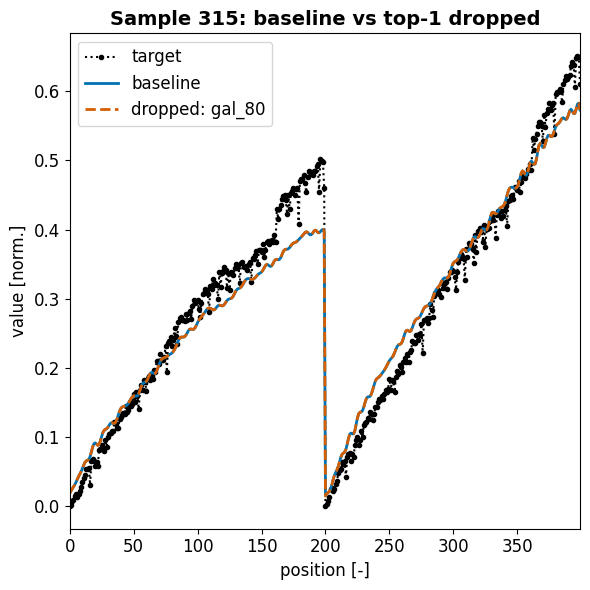

In [38]:
# Baseline vs dropped prediction for SAMPLE_IDX (top-1 variable masked)
import torch
import torch.nn.functional as F
from proT.evaluation.predict import predict_test_from_ckpt

ctrl_idx = config['data']['features']['X']['variable']  # variable id feature
intv_idx = config['data']['features']['X']['value']     # value feature masked
y_val_idx = config['data']['val_idx']                   # target value feature
top_var = int(row['sens_1'])

def drop_top_var_fn(X):
    """Set value to NaN where variable == top_var, only for SAMPLE_IDX."""
    X = X.clone()
    # Global batch offset is unknown inside the hook, so track it via a counter
    start = drop_top_var_fn.offset
    drop_top_var_fn.offset += X.shape[0]
    local = SAMPLE_IDX - start
    if 0 <= local < X.shape[0]:
        m = X[local, :, ctrl_idx] == top_var
        X[local, m, intv_idx] = float('nan')
    return X
drop_top_var_fn.offset = 0

res_base = predict_test_from_ckpt(config, datadir_path, checkpoint_path, dataset_label='test')
res_drop = predict_test_from_ckpt(config, datadir_path, checkpoint_path, dataset_label='test',
                                  input_conditioning_fn=drop_top_var_fn)

def mu_sigma(outputs, i, eps=1e-3):
    """Return (mu, sigma or None) of sample i."""
    o = np.asarray(outputs)[i]
    if o.ndim == 2 and o.shape[-1] >= 2:
        sig = (F.softplus(torch.from_numpy(o[:, 1].astype(np.float32))) + eps).numpy()
        return o[:, 0], sig
    return o.reshape(-1), None

mu_b, sig_b = mu_sigma(res_base.outputs, SAMPLE_IDX)
mu_d, sig_d = mu_sigma(res_drop.outputs, SAMPLE_IDX)
tgt = np.asarray(res_base.targets)[SAMPLE_IDX]
tgt = tgt[:, y_val_idx] if tgt.ndim == 2 else tgt.reshape(-1)
x = np.arange(len(mu_b))

# Colorblind (Okabe-Ito) palette
c_tgt, c_base, c_drop = '#000000', '#0072B2', '#D55E00'
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(x, tgt[:len(x)], color=c_tgt, ls=':', marker='.', label='target')
ax.plot(x, mu_b, color=c_base, lw=2, label='baseline')
ax.plot(x, mu_d, color=c_drop, lw=2, ls='--', label=f'dropped: {name_of(top_var)}')
if sig_b is not None:
    ax.fill_between(x, mu_b - sig_b, mu_b + sig_b, color=c_base, alpha=0.15)
    ax.fill_between(x, mu_d - sig_d, mu_d + sig_d, color=c_drop, alpha=0.15)
ax.set_xlim(x.min(), x.max())
ax.set_xlabel('position [-]', fontsize=12)
ax.set_ylabel('value [norm.]', fontsize=12)
ax.tick_params(labelsize=12)
ax.set_title(f'Sample {SAMPLE_IDX}: baseline vs top-1 dropped', fontsize=14, fontweight='bold')
ax.legend(fontsize=12)
fig.tight_layout()

SAVE_FIG = False
if SAVE_FIG:
    fig_base = join(dirname(output_path), f'baseline_vs_dropped_sample{SAMPLE_IDX}')
    for ext in ('svg', 'pdf', 'png'):
        fig.savefig(f'{fig_base}.{ext}', dpi=300, bbox_inches='tight')
plt.show()